       SMART AGRICULTURE INTELLIGENCE SYSTEM

[1] Generating Agricultural Dataset...
Dataset Created: (2000, 9)


,N,P,K,temperature,humidity,ph,rainfall,crop,yield
0,38.397186,65.154331,49.738608,28.421125,58.582212,6.456548,89.780742,Soybean,2.666092
1,29.086359,19.191219,24.748302,30.571550,33.531420,6.085608,84.007394,Millets,1.889248
2,60.730730,51.034412,42.489560,27.590332,69.665692,6.720443,219.510896,Rice,4.125049
3,114.266616,48.490064,73.756980,27.498403,72.958144,6.589403,237.045564,Sugarcane,78.941559
4,58.562738,63.731189,41.135270,22.103074,68.962790,6.253441,102.441214,Soybean,2.600217



[2] Exploratory Data Analysis

Missing Values:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
crop           0
yield          0
dtype: int64


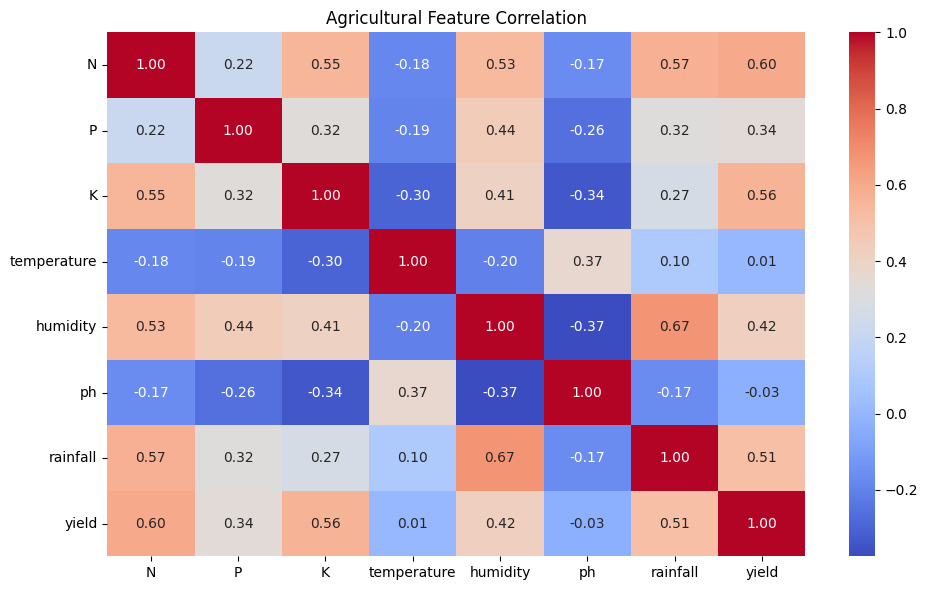

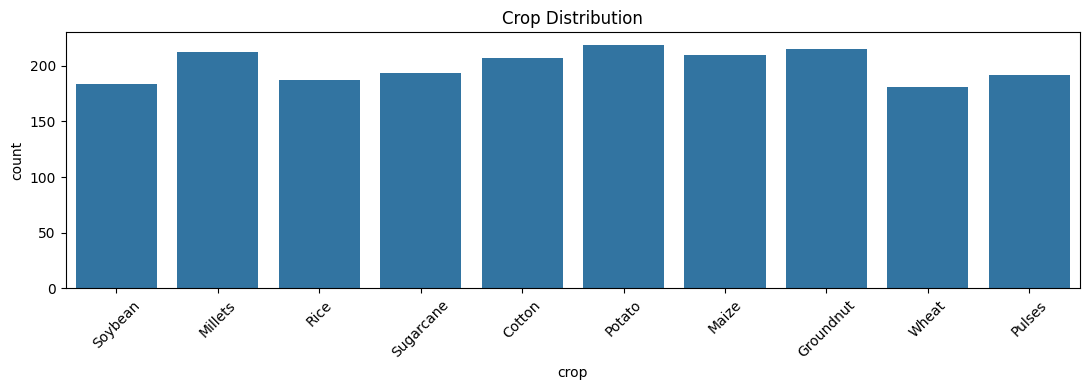


[3] Training Crop Yield Prediction Model...
MAE: 0.573
RMSE: 1.377
R2 Score: 0.996


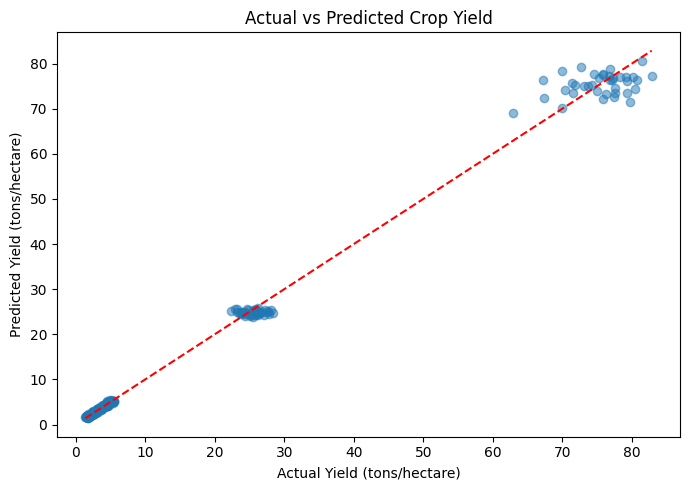


[4] Training Crop Recommendation Model...
Accuracy: 87.5 %

Classification Report:
              precision    recall  f1-score   support

      Cotton       0.92      0.88      0.90        41
   Groundnut       0.68      0.74      0.71        43
       Maize       0.80      0.88      0.84        42
     Millets       0.95      1.00      0.98        42
      Potato       1.00      0.98      0.99        44
      Pulses       0.76      0.74      0.75        39
        Rice       0.95      0.95      0.95        37
     Soybean       0.85      0.76      0.80        37
   Sugarcane       0.95      0.95      0.95        39
       Wheat       0.91      0.86      0.89        36

    accuracy                           0.88       400
   macro avg       0.88      0.87      0.88       400
weighted avg       0.88      0.88      0.88       400



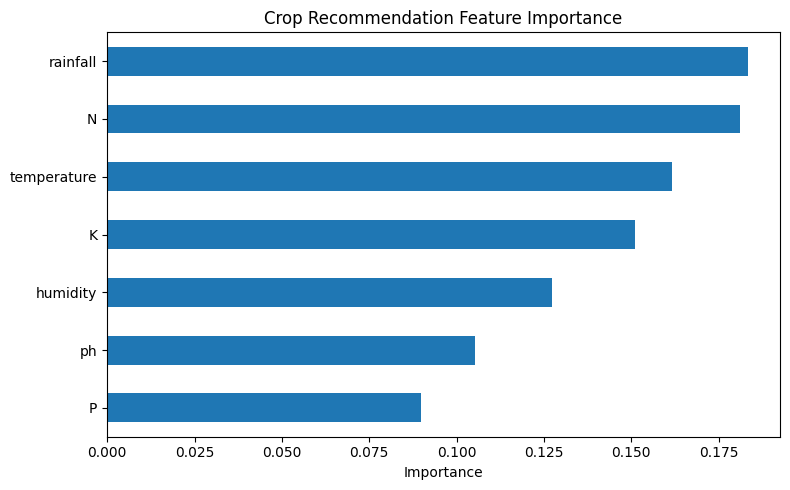


[5] Training Agricultural Pattern Detection Model...
Silhouette Score: 0.289

Cluster Characteristics:


,N,P,K,temperature,humidity,ph,rainfall,yield
cluster,,,,,,,,
0,40.26,28.25,33.58,31.20,43.43,7.04,73.51,1.87
1,90.54,53.99,84.03,18.86,69.54,5.79,110.25,24.51
2,98.98,52.91,56.63,28.18,76.66,6.51,205.19,37.08
3,55.90,49.66,43.13,25.27,59.31,6.61,105.59,2.90


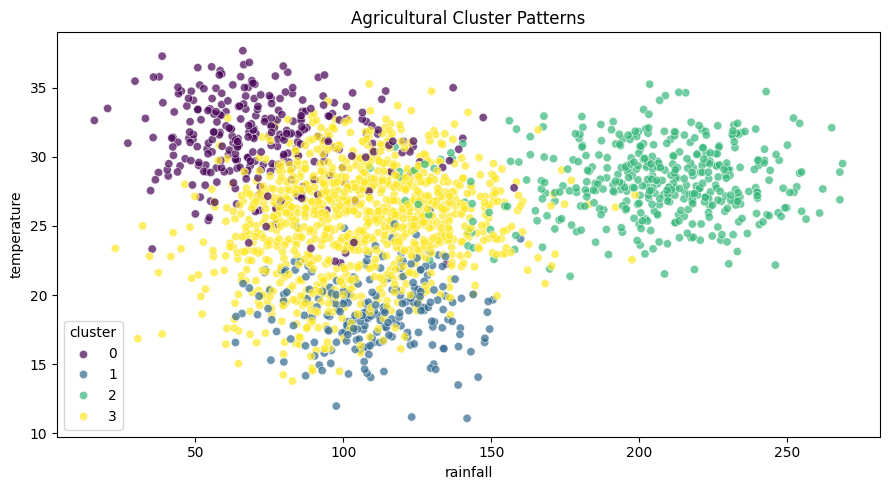


[6] Training Weather Forecasting Models...
temperature MAE: 1.94
rainfall MAE: 4.25
humidity MAE: 6.78

30-Day Forecast:


,temperature,rainfall,humidity
date,,,
2025-12-31,26.49,3.80,64.68
2026-01-01,26.60,3.61,63.44
2026-01-02,26.70,3.51,64.26
2026-01-03,26.81,3.40,63.68
2026-01-04,26.91,3.30,64.10
2026-01-05,27.02,3.20,63.80
2026-01-06,27.12,3.10,64.01
2026-01-07,27.22,3.00,63.86
2026-01-08,27.33,2.90,63.97


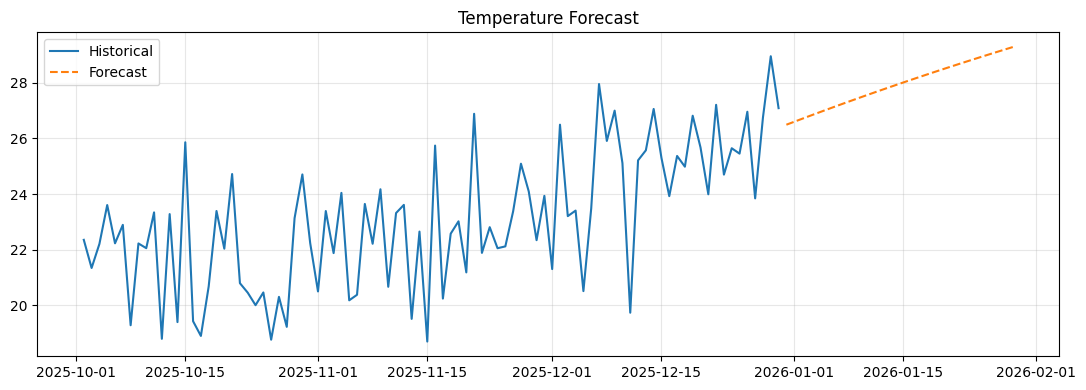

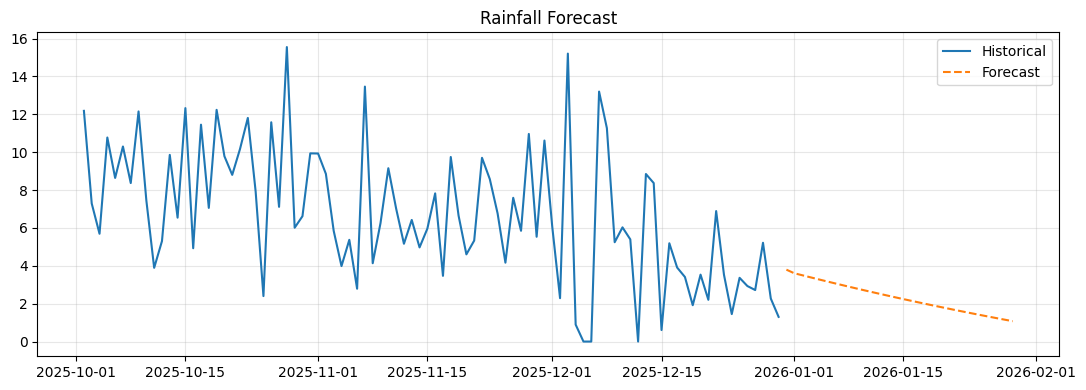

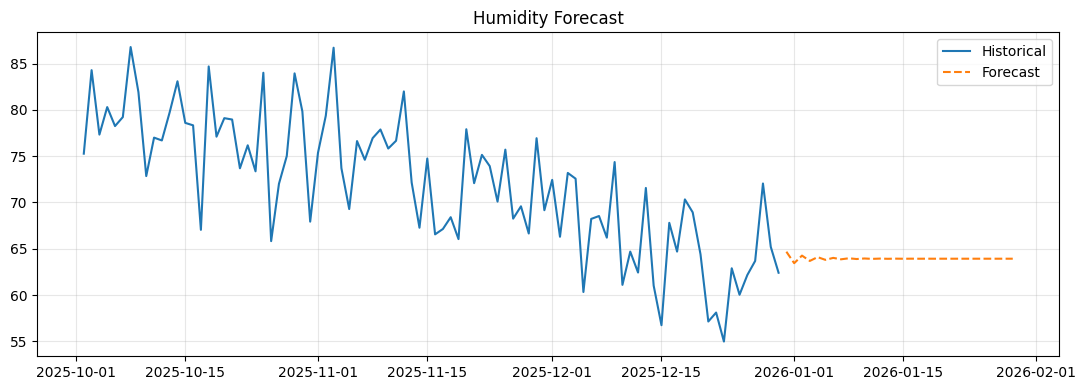


[8] Launching Interactive Agriculture Dashboard...


HTML(value='<h2>Smart Agriculture Intelligence Dashboard</h2><p>Enter soil and climate information below.</p>'…

IntSlider(value=80, description='Nitrogen:', max=150, style=SliderStyle(description_width='150px'))

IntSlider(value=40, description='Phosphorus:', max=150, style=SliderStyle(description_width='150px'))

IntSlider(value=40, description='Potassium:', max=150, style=SliderStyle(description_width='150px'))

...

FloatSlider(value=180.0, description='Rainfall (mm):', max=350.0, style=SliderStyle(description_width='150px')…

Dropdown(description='Crop:', options=('Rice', 'Wheat', 'Maize', 'Cotton', 'Sugarcane', 'Groundnut', 'Soybean'…

Button(button_style='success', description='Analyze Agriculture Data', icon='check', style=ButtonStyle())

Output()


All models and datasets saved successfully!
Project ready for demonstration.


In [1]:

# SMART AGRICULTURE INTELLIGENCE SYSTEM

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score, classification_report,
    mean_absolute_error, mean_squared_error,
    r2_score, silhouette_score
)
from statsmodels.tsa.arima.model import ARIMA
import ipywidgets as widgets
from IPython.display import display, clear_output

warnings.filterwarnings("ignore")
np.random.seed(42)

print("=" * 65)
print("       SMART AGRICULTURE INTELLIGENCE SYSTEM")
print("=" * 65)

# 1. CREATE SYNTHETIC AGRICULTURAL DATASET


print("\n[1] Generating Agricultural Dataset...")

n = 2000

crop_profiles = {
    "Rice":       [90, 45, 45, 28, 80, 6.2, 220],
    "Wheat":      [80, 40, 40, 20, 55, 6.8, 90],
    "Maize":      [85, 50, 45, 26, 65, 6.5, 130],
    "Cotton":     [70, 40, 55, 30, 55, 7.0, 100],
    "Sugarcane":  [110, 60, 70, 29, 75, 6.8, 200],
    "Groundnut":  [35, 55, 40, 27, 60, 6.3, 100],
    "Soybean":    [45, 60, 45, 25, 65, 6.5, 130],
    "Millets":    [35, 25, 30, 32, 40, 7.0, 65],
    "Pulses":     [30, 45, 35, 25, 55, 6.7, 85],
    "Potato":     [90, 55, 85, 19, 70, 5.8, 110]
}

columns = [
    "N", "P", "K", "temperature",
    "humidity", "ph", "rainfall"
]

records = []

for i in range(n):
    crop = np.random.choice(list(crop_profiles.keys()))
    profile = np.array(crop_profiles[crop])

    noise = np.random.normal(
        0, [12, 10, 10, 2.5, 7, 0.35, 20]
    )

    values = profile + noise

    values = np.clip(
        values,
        [0, 0, 0, 5, 10, 3.5, 0],
        [150, 150, 150, 45, 100, 9, 350]
    )

    record = dict(zip(columns, values))
    record["crop"] = crop
    records.append(record)

data = pd.DataFrame(records)

# Synthetic yield target
crop_yield_base = {
    "Rice": 4.0, "Wheat": 3.5, "Maize": 5.0,
    "Cotton": 2.0, "Sugarcane": 70.0,
    "Groundnut": 2.5, "Soybean": 2.8,
    "Millets": 2.0, "Pulses": 1.8,
    "Potato": 25.0
}

data["yield"] = data.apply(
    lambda r:
        crop_yield_base[r["crop"]]
        * (
            1
            + 0.001 * (r["N"] - 70)
            + 0.0005 * (r["rainfall"] - 120)
            - 0.015 * abs(r["ph"] - 6.5)
        )
        + np.random.normal(
            0, crop_yield_base[r["crop"]] * 0.06
        ),
    axis=1
).clip(lower=0.1)

data.to_csv("agriculture_dataset.csv", index=False)

print("Dataset Created:", data.shape)
display(data.head())


# 2. EXPLORATORY DATA ANALYSIS


print("\n[2] Exploratory Data Analysis")

print("\nMissing Values:")
print(data.isnull().sum())

plt.figure(figsize=(10, 6))
sns.heatmap(
    data.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Agricultural Feature Correlation")
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 4))
sns.countplot(data=data, x="crop")
plt.xticks(rotation=45)
plt.title("Crop Distribution")
plt.tight_layout()
plt.show()

# . CROP YIELD PREDICTION
# RANDOM FOREST REGRESSION


print("\n[3] Training Crop Yield Prediction Model...")

yield_features = columns + ["crop"]

# One-hot encoding avoids arbitrary crop ordering
X_yield = pd.get_dummies(
    data[yield_features],
    columns=["crop"],
    dtype=int
)

yield_columns = X_yield.columns.tolist()
y_yield = data["yield"]

Xy_train, Xy_test, yy_train, yy_test = train_test_split(
    X_yield, y_yield,
    test_size=0.2,
    random_state=42
)

yield_model = RandomForestRegressor(
    n_estimators=150,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

yield_model.fit(Xy_train, yy_train)

yield_pred = yield_model.predict(Xy_test)

print("MAE:", round(mean_absolute_error(yy_test, yield_pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(yy_test, yield_pred)), 3))
print("R2 Score:", round(r2_score(yy_test, yield_pred), 3))

plt.figure(figsize=(7, 5))
plt.scatter(yy_test, yield_pred, alpha=0.5)
plt.plot(
    [yy_test.min(), yy_test.max()],
    [yy_test.min(), yy_test.max()],
    "r--"
)
plt.xlabel("Actual Yield (tons/hectare)")
plt.ylabel("Predicted Yield (tons/hectare)")
plt.title("Actual vs Predicted Crop Yield")
plt.tight_layout()
plt.show()


# . CROP RECOMMENDATION
# RANDOM FOREST CLASSIFICATION


print("\n[4] Training Crop Recommendation Model...")

X_crop = data[columns]
y_crop = data["crop"]

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_crop, y_crop,
    test_size=0.2,
    random_state=42,
    stratify=y_crop
)

crop_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

crop_model.fit(Xc_train, yc_train)

crop_pred = crop_model.predict(Xc_test)

print("Accuracy:", round(accuracy_score(yc_test, crop_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(yc_test, crop_pred, zero_division=0))

importance = pd.Series(
    crop_model.feature_importances_,
    index=columns
).sort_values()

plt.figure(figsize=(8, 5))
importance.plot(kind="barh")
plt.title("Crop Recommendation Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


# . AGRICULTURAL PATTERN DETECTION
# K-MEANS CLUSTERING


print("\n[5] Training Agricultural Pattern Detection Model...")

# Use only input features for clustering
cluster_features = columns

scaler = StandardScaler()
scaled_data = scaler.fit_transform(data[cluster_features])

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

data["cluster"] = kmeans.fit_predict(scaled_data)

score = silhouette_score(
    scaled_data, data["cluster"],
    sample_size=1000,
    random_state=42
)

print("Silhouette Score:", round(score, 3))

print("\nCluster Characteristics:")
display(
    data.groupby("cluster")[cluster_features + ["yield"]]
    .mean().round(2)
)

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=data,
    x="rainfall",
    y="temperature",
    hue="cluster",
    palette="viridis",
    alpha=0.7
)
plt.title("Agricultural Cluster Patterns")
plt.tight_layout()
plt.show()


#  AGRICULTURAL CONDITION FORECASTING
# ARIMA TIME SERIES


print("\n[6] Training Weather Forecasting Models...")

dates = pd.date_range(
    start="2023-01-01",
    periods=1095,
    freq="D"
)

days = np.arange(len(dates))

weather = pd.DataFrame({
    "temperature":
        27 + 6 * np.sin(2 * np.pi * days / 365)
        + np.random.normal(0, 2, len(days)),

    "rainfall":
        np.maximum(
            0,
            4 + 5 * np.sin(2 * np.pi * (days - 170) / 365)
            + np.random.normal(0, 3, len(days))
        ),

    "humidity":
        np.clip(
            65 + 15 * np.sin(2 * np.pi * (days - 170) / 365)
            + np.random.normal(0, 5, len(days)),
            20, 100
        )
}, index=dates)

weather.index.name = "date"

forecast_data = {}
forecast_metrics = {}

for feature in ["temperature", "rainfall", "humidity"]:

    series = weather[feature]
    train = series.iloc[:-30]
    test = series.iloc[-30:]

    evaluation_model = ARIMA(
        train,
        order=(2, 1, 2)
    ).fit()

    test_prediction = evaluation_model.forecast(steps=30)

    mae = mean_absolute_error(test, test_prediction)
    forecast_metrics[feature] = mae

    print(feature, "MAE:", round(mae, 2))

    # Refit on all available observations
    final_model = ARIMA(
        series,
        order=(2, 1, 2)
    ).fit()

    forecast_data[feature] = final_model.forecast(steps=30).to_numpy()

future_dates = pd.date_range(
    weather.index[-1] + pd.Timedelta(days=1),
    periods=30,
    freq="D"
)

forecast_df = pd.DataFrame(
    forecast_data,
    index=future_dates
)

forecast_df.index.name = "date"
forecast_df["rainfall"] = forecast_df["rainfall"].clip(lower=0)
forecast_df["humidity"] = forecast_df["humidity"].clip(0, 100)

print("\n30-Day Forecast:")
display(forecast_df.head(10).round(2))

for feature in ["temperature", "rainfall", "humidity"]:
    plt.figure(figsize=(11, 4))
    plt.plot(
        weather.index[-90:],
        weather[feature].iloc[-90:],
        label="Historical"
    )
    plt.plot(
        forecast_df.index,
        forecast_df[feature],
        "--",
        label="Forecast"
    )
    plt.title(feature.title() + " Forecast")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

#. INTEGRATED PREDICTION FUNCTION


def smart_agriculture_system(
    N, P, K, temperature,
    humidity, ph, rainfall, crop
):

    crop = crop.title()

    if crop not in crop_profiles:
        print("Invalid crop selected.")
        return

    sample = pd.DataFrame([{
        "N": N,
        "P": P,
        "K": K,
        "temperature": temperature,
        "humidity": humidity,
        "ph": ph,
        "rainfall": rainfall
    }])

    # Crop Recommendation
    recommended = crop_model.predict(sample)[0]

    probabilities = crop_model.predict_proba(sample)[0]
    top_indices = np.argsort(probabilities)[::-1][:3]

    # Yield Prediction
    yield_input = sample.copy()
    yield_input["crop"] = crop

    yield_input = pd.get_dummies(
        yield_input,
        columns=["crop"],
        dtype=int
    )

    yield_input = yield_input.reindex(
        columns=yield_columns,
        fill_value=0
    )

    predicted_yield = yield_model.predict(yield_input)[0]

    # Clustering
    cluster_input = scaler.transform(sample)
    cluster = int(kmeans.predict(cluster_input)[0])

    print("\n" + "=" * 55)
    print("       SMART AGRICULTURE INTELLIGENCE REPORT")
    print("=" * 55)

    print("\nCROP YIELD PREDICTION")
    print("Selected Crop:", crop)
    print("Predicted Yield:", round(predicted_yield, 2), "tons/hectare")

    print("\nCROP RECOMMENDATION")
    print("Recommended Crop:", recommended)
    print("\nTop 3 Model Recommendations:")

    for idx in top_indices:
        print(
            crop_model.classes_[idx],
            ":",
            round(probabilities[idx] * 100, 2),
            "%"
        )

    print("\nAGRICULTURAL PATTERN DETECTION")
    print("Cluster:", cluster)
    print("Cluster numbers represent similar environmental profiles.")

    print("\nAGRICULTURAL WEATHER FORECAST")
    print("Forecast Period:", future_dates[0].date(),
          "to", future_dates[-1].date())

    print(
        "Average Temperature:",
        round(forecast_df["temperature"].mean(), 2),
        "°C"
    )

    print(
        "Total Rainfall:",
        round(forecast_df["rainfall"].sum(), 2),
        "mm"
    )

    print(
        "Average Humidity:",
        round(forecast_df["humidity"].mean(), 2),
        "%"
    )

    print("\n" + "=" * 55)


print("\n[8] Launching Interactive Agriculture Dashboard...")

style = {"description_width": "150px"}

N_widget = widgets.IntSlider(
    value=80, min=0, max=150,
    description="Nitrogen:", style=style
)

P_widget = widgets.IntSlider(
    value=40, min=0, max=150,
    description="Phosphorus:", style=style
)

K_widget = widgets.IntSlider(
    value=40, min=0, max=150,
    description="Potassium:", style=style
)

temp_widget = widgets.FloatSlider(
    value=28, min=5, max=45,
    description="Temperature:", style=style
)

humidity_widget = widgets.FloatSlider(
    value=75, min=10, max=100,
    description="Humidity:", style=style
)

ph_widget = widgets.FloatSlider(
    value=6.5, min=3.5, max=9,
    step=0.1, description="Soil pH:", style=style
)

rain_widget = widgets.FloatSlider(
    value=180, min=0, max=350,
    description="Rainfall (mm):", style=style
)

crop_widget = widgets.Dropdown(
    options=list(crop_profiles.keys()),
    value="Rice",
    description="Crop:", style=style
)

predict_button = widgets.Button(
    description="Analyze Agriculture Data",
    button_style="success",
    icon="check"
)

output = widgets.Output()

def run_prediction(button):
    with output:
        clear_output(wait=True)

        smart_agriculture_system(
            N_widget.value,
            P_widget.value,
            K_widget.value,
            temp_widget.value,
            humidity_widget.value,
            ph_widget.value,
            rain_widget.value,
            crop_widget.value
        )

predict_button.on_click(run_prediction)

display(
    widgets.HTML(
        "<h2>Smart Agriculture Intelligence Dashboard</h2>"
        "<p>Enter soil and climate information below.</p>"
    ),
    N_widget,
    P_widget,
    K_widget,
    temp_widget,
    humidity_widget,
    ph_widget,
    rain_widget,
    crop_widget,
    predict_button,
    output
)

joblib.dump(yield_model, "crop_yield_model.pkl")
joblib.dump(yield_columns, "yield_feature_columns.pkl")
joblib.dump(crop_model, "crop_recommendation_model.pkl")
joblib.dump(kmeans, "crop_pattern_model.pkl")
joblib.dump(scaler, "agriculture_scaler.pkl")

data.to_csv("agriculture_dataset.csv", index=False)
weather.to_csv("historical_weather.csv")
forecast_df.to_csv("agriculture_forecast.csv")

print("\nAll models and datasets saved successfully!")
print("Project ready for demonstration.")